In [1]:
import pandas as pd
from sklearn.decomposition import FastICA
import matplotlib.pyplot as plt
from scipy.spatial import procrustes
from scipy.stats import wasserstein_distance
import numpy as np

In [ ]:
#import dataset
#SOURCE
expr_file1= r"C:\Zmyfiles\codes\research\KPCA-DA\KPCA-DA\examples\Data\cptacvssmc\smc_labelsNL.csv"
expr1 = pd.read_csv(expr_file1, encoding='utf-8', engine='python')

#TARGET_test_unadjusted
expr_file2= r"C:\Zmyfiles\codes\research\KPCA-DA\KPCA-DA\examples\Data\cptacvssmc\target_test.csv"
expr2 = pd.read_csv(expr_file2, encoding='utf-8', engine='python')

#TARGET_test_adjusted
expr_file3= r"C:\Zmyfiles\codes\research\KPCA-DA\KPCA-DA\examples\Data\cptacvssmc\test_set_corrected.csv"
expr_file3 = pd.read_csv(expr_file3, encoding='utf-8', engine='python')

expr_file4= r"C:\Zmyfiles\codes\research\KPCA-DA\KPCA-DA\examples\Data\cptacvssmc\aligned_smc.csv"
expr4 = pd.read_csv(expr_file4, encoding='utf-8', engine='python')

In [2]:
#import dataset
#SOURCE
expr_file1= r"C:\Zmyfiles\codes\research\KPCA-DA\KPCA-DA\examples\Data\TvsN\TCGA_BRCA_NvT_new.csv"
expr1 = pd.read_csv(expr_file1, encoding='utf-8', engine='python')

#TARGET_test_unadjusted
expr_file2= r"C:\Zmyfiles\codes\research\KPCA-DA\KPCA-DA\examples\Data\TvsN\GSE45498_NvT.csv"
expr2 = pd.read_csv(expr_file2, encoding='utf-8', engine='python')

#TARGET_test_adjusted
expr_file3= r"C:\Zmyfiles\codes\research\KPCA-DA\KPCA-DA\examples\Data\TvsN\aligned_tcga.csv"
expr_file3 = pd.read_csv(expr_file3, encoding='utf-8', engine='python')

expr_file4= r"C:\Zmyfiles\codes\research\KPCA-DA\KPCA-DA\examples\Data\TvsN\aligned_gse.csv"
expr4 = pd.read_csv(expr_file4, encoding='utf-8', engine='python')

In [ ]:
# Check the shapes of the datasets
print(f"expr1 shape: {expr1.shape}")
print(f"expr2 shape: {expr2.shape}")
print(f"expr_file3 shape: {expr_file3.shape}")
print(f"\nAfter transpose:")
print(f"expr1_ica would be: {expr1.drop('Hugo_Symbol', axis=1).T.shape}")
print(f"expr2_ica would be: {expr_file3.drop('Hugo_Symbol', axis=1).T.shape}")

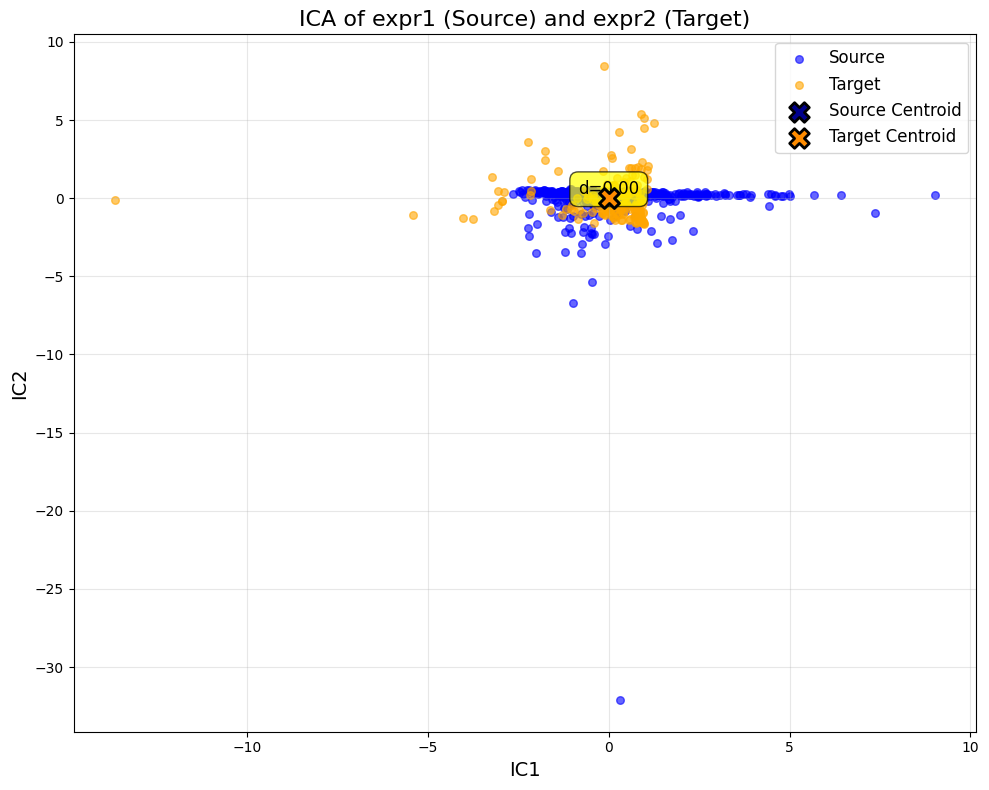

Centroid distance: 0.0000


In [25]:
# Prepare data for ICA (remove 'Hugo_Symbol' column and transpose so samples are rows)
expr1_ica = expr1.drop('Hugo_Symbol', axis=1).iloc[:-1].T
expr2_ica = expr2.drop('gene', axis=1).iloc[:-1].T

# Fit ICA on expr1 and transform both datasets
ica_model = FastICA(n_components=2, random_state=15, max_iter=500, tol=0.0001, whiten='unit-variance', fun='exp')
expr1_embedded = ica_model.fit_transform(expr1_ica)

# For ICA, we need to transform expr2 using the same unmixing matrix
expr2_embedded = ica_model.fit_transform(expr2_ica)

# Scale the embeddings to increase dispersion
scale_factor = 1.5
expr1_embedded_scaled = expr1_embedded * scale_factor
expr2_embedded_scaled = expr2_embedded * scale_factor

# Calculate centroids
centroid1 = expr1_embedded_scaled.mean(axis=0)
centroid2 = expr2_embedded_scaled.mean(axis=0)

# Calculate distance between centroids
distance = np.linalg.norm(centroid1 - centroid2)

# Plot both datasets in the same figure
plt.figure(figsize=(10, 8))
plt.scatter(expr1_embedded_scaled[:, 0], expr1_embedded_scaled[:, 1], s=30, alpha=0.6, c='blue', label='Source')
plt.scatter(expr2_embedded_scaled[:, 0], expr2_embedded_scaled[:, 1], s=30, alpha=0.6, c='orange', label='Target')

# Plot centroids
plt.scatter(centroid1[0], centroid1[1], s=200, c='darkblue', marker='X', edgecolors='black', linewidths=2, label='Source Centroid', zorder=5)
plt.scatter(centroid2[0], centroid2[1], s=200, c='darkorange', marker='X', edgecolors='black', linewidths=2, label='Target Centroid', zorder=5)

# Draw line between centroids
plt.plot([centroid1[0], centroid2[0]], [centroid1[1], centroid2[1]], 'k--', linewidth=2, alpha=0.7)

# Add distance annotation on the line
mid_point = [(centroid1[0] + centroid2[0]) / 2, (centroid1[1] + centroid2[1]) / 2]
plt.text(mid_point[0], mid_point[1], f'd={distance:.2f}', fontsize=12, 
         bbox=dict(boxstyle='round,pad=0.5', facecolor='yellow', alpha=0.7),
         ha='center', va='bottom')

plt.title('ICA of expr1 (Source) and expr2 (Target)', fontsize=16)
plt.xlabel('IC1', fontsize=14)
plt.ylabel('IC2', fontsize=14)
plt.legend(fontsize=12)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Centroid distance: {distance:.4f}")


In [11]:
# Prepare data for ICA (remove 'Hugo_Symbol' column and transpose so samples are rows)
expr1_ica = (expr1.drop('gene', axis=1).iloc[:-1]).T
expr2_ica = expr2.drop('gene', axis=1).T

# Fit ICA on expr1 and transform both datasets
ica_model = FastICA(n_components=2, random_state=6, max_iter=1000, tol=0.001)
expr1_embedded = ica_model.fit_transform(expr1_ica)
expr2_embedded = ica_model.fit_transform(expr2_ica)

# Plot both datasets in the same plot
plt.figure(figsize=(10, 8))
plt.scatter(expr1_embedded[:, 0], expr1_embedded[:, 1], s=30, alpha=0.6, label='Source', c='blue')
plt.scatter(expr2_embedded[:, 0], expr2_embedded[:, 1], s=30, alpha=0.6, label='Target', c='orange')
plt.title('ICA: Adaptation with Combat', fontsize=20)
plt.xlabel('Source Dataset: TCGA', fontsize=20)
plt.ylabel('Target Dataset: GEO', fontsize=20)
plt.legend(fontsize=18)
plt.tight_layout()
plt.show()

KeyError: "['gene'] not found in axis"

In [26]:
# Calculate Wasserstein distances for ICA embeddings
emd_x = wasserstein_distance(expr1_embedded[:,0], expr2_embedded[:,0])
emd_y = wasserstein_distance(expr1_embedded[:,1], expr2_embedded[:,1])

emd_combined = np.sqrt(emd_x**2 + emd_y**2)

print(f"Wasserstein distance X-axis: {emd_x:.4f}")
print(f"Wasserstein distance Y-axis: {emd_y:.4f}")
print(f"Combined Wasserstein distance (scalar): {emd_combined:.4f}")

Wasserstein distance X-axis: 0.5792
Wasserstein distance Y-axis: 0.6739
Combined Wasserstein distance (scalar): 0.8887


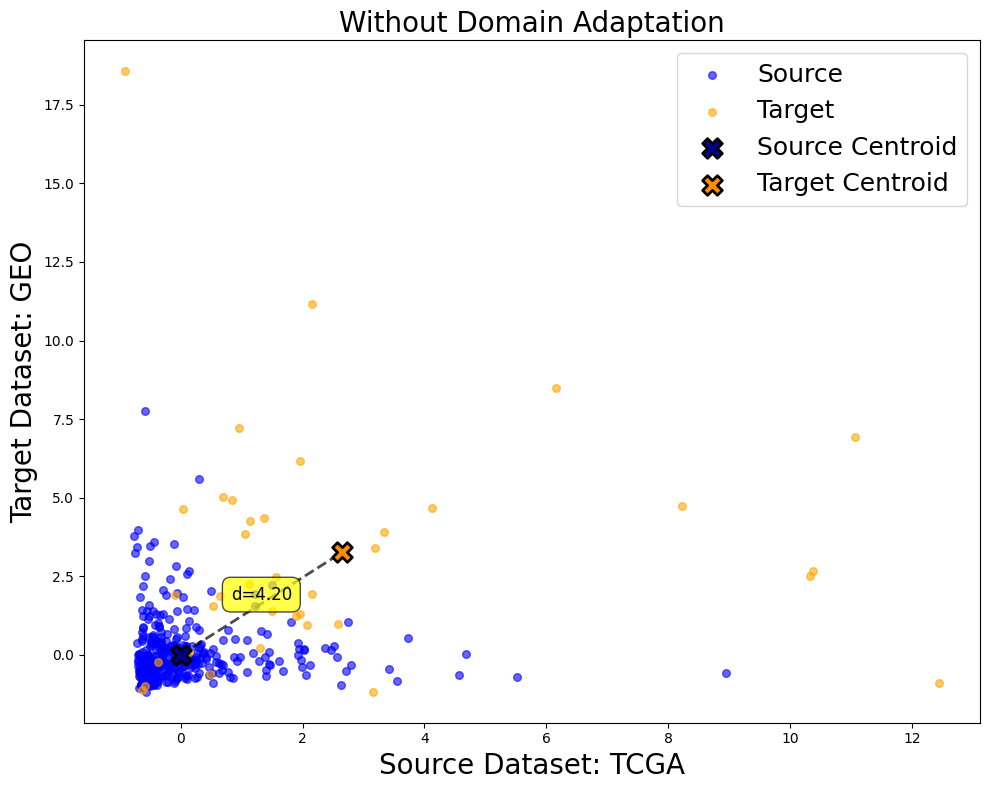

Centroid distance: 4.1980


In [23]:
# Prepare data for ICA with adjusted datasets
expr3_ica = expr_file3.T
expr4_ica = expr4.drop('Hugo_Symbol', axis=1).T

# Fit ICA on expr3 and transform both datasets
ica_model2 = FastICA(n_components=2, random_state=42, max_iter=1000, tol=0.001)
expr3_embedded = ica_model2.fit_transform(expr3_ica)
expr4_embedded = ica_model2.transform(expr4_ica)

# Calculate centroids
centroid3 = expr3_embedded.mean(axis=0)
centroid4 = expr4_embedded.mean(axis=0)

# Calculate distance between centroids
distance = np.linalg.norm(centroid3 - centroid4)

# Plot both datasets in the same plot
plt.figure(figsize=(10, 8))
plt.scatter(expr3_embedded[:, 0], expr3_embedded[:, 1], s=30, alpha=0.6, label='Source', c='blue')
plt.scatter(expr4_embedded[:, 0], expr4_embedded[:, 1], s=30, alpha=0.6, label='Target', c='orange')

# Plot centroids
plt.scatter(centroid3[0], centroid3[1], s=200, c='darkblue', marker='X', edgecolors='black', linewidths=2, label='Source Centroid', zorder=5)
plt.scatter(centroid4[0], centroid4[1], s=200, c='darkorange', marker='X', edgecolors='black', linewidths=2, label='Target Centroid', zorder=5)

# Draw line between centroids
plt.plot([centroid3[0], centroid4[0]], [centroid3[1], centroid4[1]], 'k--', linewidth=2, alpha=0.7)

# Add distance annotation on the line
mid_point = [(centroid3[0] + centroid4[0]) / 2, (centroid3[1] + centroid4[1]) / 2]
plt.text(mid_point[0], mid_point[1], f'd={distance:.2f}', fontsize=12, 
         bbox=dict(boxstyle='round,pad=0.5', facecolor='yellow', alpha=0.7),
         ha='center', va='bottom')

plt.title('Without Domain Adaptation', fontsize=20)
plt.xlabel('Source Dataset: TCGA', fontsize=20)
plt.ylabel('Target Dataset: GEO', fontsize=20)
plt.legend(fontsize=18)
plt.tight_layout()
plt.show()

print(f"Centroid distance: {distance:.4f}")


In [27]:
# Calculate Wasserstein distances for ComBat-adjusted data
emd_x = wasserstein_distance(expr3_embedded[:,0], expr4_embedded[:,0])
emd_y = wasserstein_distance(expr3_embedded[:,1], expr4_embedded[:,1])

emd_combined = np.sqrt(emd_x**2 + emd_y**2)

print(f"Wasserstein distance X-axis: {emd_x:.4f}")
print(f"Wasserstein distance Y-axis: {emd_y:.4f}")
print(f"Combined Wasserstein distance (scalar): {emd_combined:.4f}")

Wasserstein distance X-axis: 2.6589
Wasserstein distance Y-axis: 3.2808
Combined Wasserstein distance (scalar): 4.2230


In [ ]:
# Drop the 'Hugo_Symbol' column and the last row from expr1
expr1_cleaned = expr1.drop('Hugo_Symbol', axis=1).iloc[:-1]
print(f"expr1_cleaned shape: {expr1_cleaned.shape}")
expr1_cleaned.head()

### Comparison: ICA vs UMAP
Compare the performance of ICA and UMAP for dimensionality reduction

In [ ]:
# You can compare ICA results with UMAP results here
# Example: side-by-side visualization of both methods